<a href="https://colab.research.google.com/github/AlfredaDhaifullah04/Pembelajaran_Mesin_2026/blob/main/TG9_JS11_Alfreda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#JOBSHEET 11 - Klasifikasi 2
## Support Vector Machine (SVM)
Pengenalan konsep dasar, optimal hyperplane, kernel trick, dan implementasi praktis klasifikasi menggunakan Scikit-Learn.

Praktikum 1 - Klasifikasi SVM dengan Data Dummy Linier

In [12]:
# Langkah 1 - import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

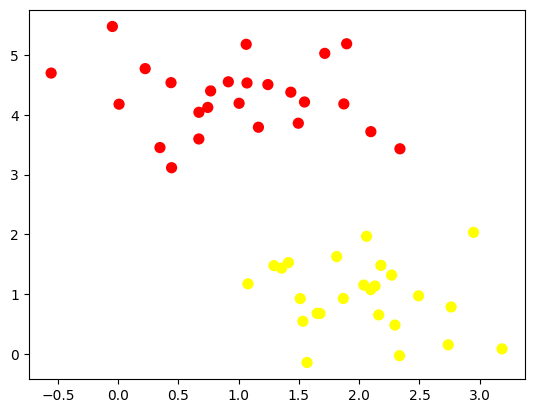

In [14]:
# Langkah 1 - Import Library

from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

(-1.0, 3.5)

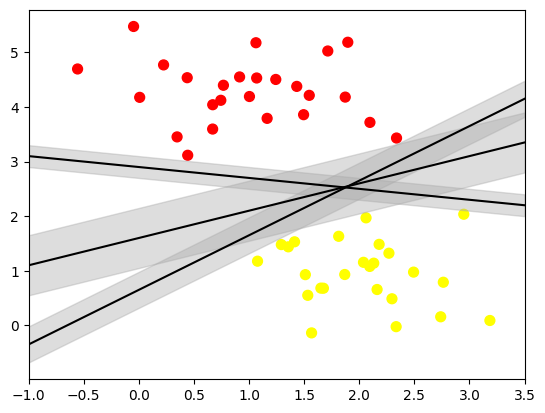

In [19]:
	xfit = np.linspace(-1, 3.5)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

	for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
	    yfit = m * xfit + b
	    plt.plot(xfit, yfit, '-k')
	    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
	                     color='#AAAAAA', alpha=0.4)

	plt.xlim(-1, 3.5)

In [21]:
	from sklearn.svm import SVC # "Support vector classifier"
	model = SVC(kernel='linear', C=1E10)
	model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

In [22]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

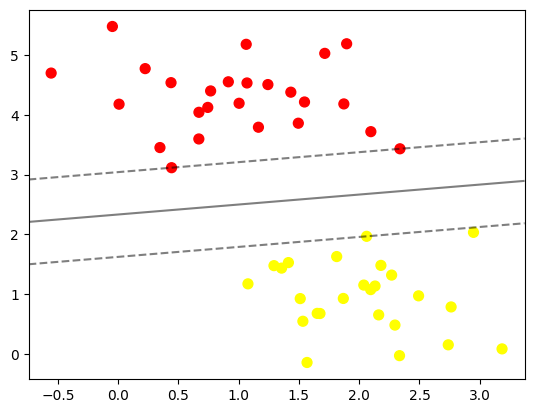

In [23]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(model)

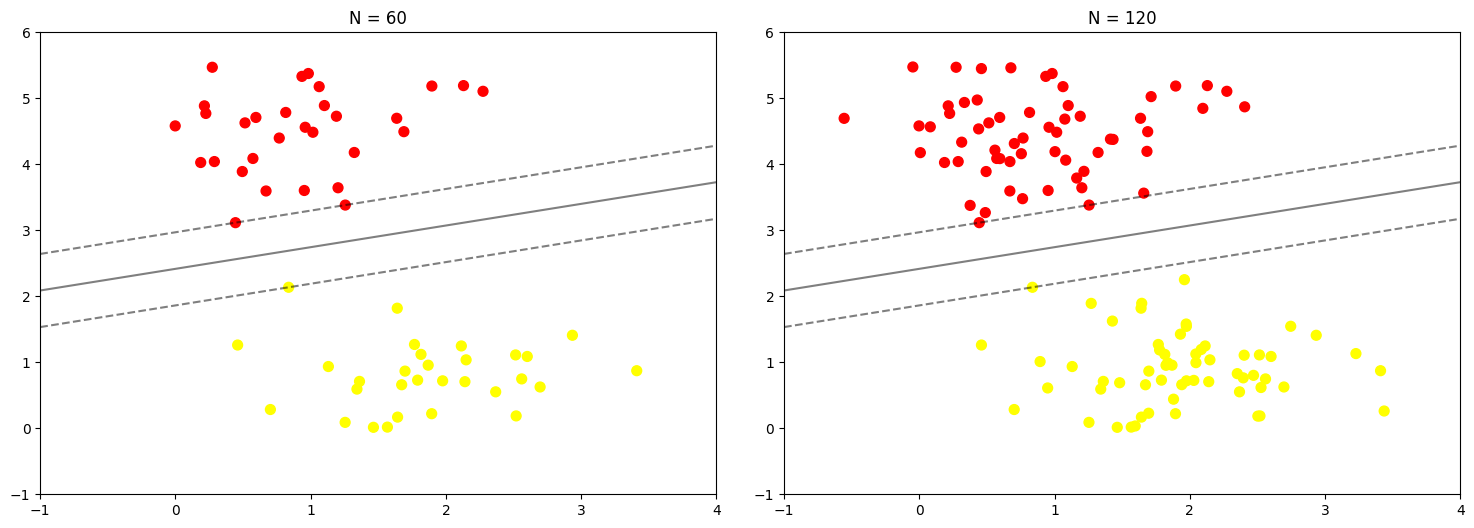

In [24]:
	def plot_svm(N=10, ax=None):
	    X, y = make_blobs(n_samples=200, centers=2,
	                      random_state=0, cluster_std=0.60)
	    X = X[:N]
	    y = y[:N]
	    model = SVC(kernel='linear', C=1E10)
	    model.fit(X, y)

	    ax = ax or plt.gca()
	    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    ax.set_xlim(-1, 4)
	    ax.set_ylim(-1, 6)
	    plot_svc_decision_function(model, ax)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
	for axi, N in zip(ax, [60, 120]):
	    plot_svm(N, axi)
	    axi.set_title('N = {0}'.format(N))

In [25]:
	# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model


	from ipywidgets import interact, fixed
	interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

Praktikum 2 - Klasifikasi SVM dengan Data Dummy Non-Linier

In [26]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC

In [27]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

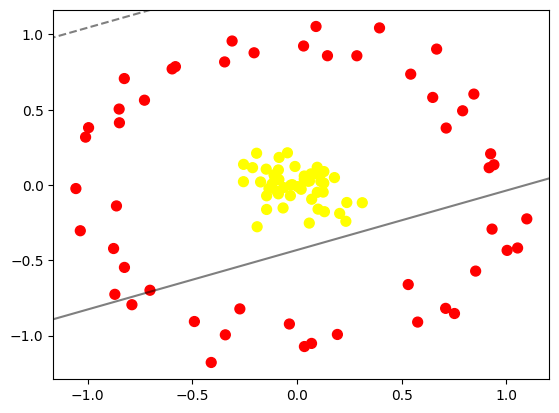

In [28]:
	# contoh data tidak terpisah secara linier
	from sklearn.datasets import make_circles
	X, y = make_circles(100, factor=.1, noise=.1)

	clf = SVC(kernel='linear').fit(X, y)

	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf, plot_support=False);

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 7.10538144e-01, -8.19319655e-01],
       [-8.23971163e-01, -5.47287803e-01],
       [-9.09990756e-03,  1.23281840e-01],
       [ 9.32332761e-01, -2.92715112e-01],
       [-3.45363937e-01,  8.17809197e-01],
       [ 9.25549506e-01,  2.07339713e-01],
       [-8.69767663e-01, -7.26067423e-01],
       [-8.24590802e-01,  7.07315915e-01],
       [-6.60934779e-02, -1.52393841e-01],
       [ 9.13102872e-02,  1.05324069e+00],
       [-7.28276844e-01,  5.63452864e-01],
       [ 5.90777294e-02, -2.52889477e-01],
       [-5.96066898e-01,  7.71459606e-01],
       [-1.06628506e-01,  5.91760409e-02],
       [ 6.98372742e-02, -1.05214161e+00],
       [-8.47948200e-01,  4.13552555e-01],
       [ 3.58582871e-02, -1.07287623e+00],
       [-9.95300544e-01,  3.81056244e-01],
       [ 2.03611794e-02, -2.81141075e-02],
       [ 2.04315092e-01, -1.88658729e-01],
       [-1.92569547e-01,  2.11152054e-01],
       [-5.80410386e-01,  7.86349439e-01],
       [ 1.45959495e-01,  8.58906350e-01],
       [ 8.51469049e-02,  7.53479835e-02],
       [ 8.45397717e-01,  6.04112780e-01],
       [-8.75846331e-01, -4.21738941e-01],
       [-2.54785364e-01,  1.37203035e-01],
       [ 1.28383379e-01,  1.29210705e-02],
       [ 1.25418304e-01, -4.68892708e-02],
       [ 7.13188770e-01,  3.78514769e-01],
       [-8.84738448e-02, -5.84492245e-02],
       [-1.05591853e+00, -2.34301495e-02],
       [ 6.73567712e-02,  7.41363672e-02],
       [-4.89805066e-01, -9.06781591e-01],
       [ 3.18560598e-02,  9.23547744e-01],
       [ 3.50144139e-02,  3.80611547e-02],
       [ 9.72752983e-02, -4.83358435e-02],
       [ 2.33887329e-01, -2.40834087e-01],
       [ 7.91741537e-01,  4.93145188e-01],
       [ 7.52747644e-01, -8.53508331e-01],
       [-8.60552907e-02,  3.59270845e-02],
       [ 3.99693356e-03, -1.07512439e-02],
       [ 1.79359209e-01,  4.93754872e-02],
       [ 8.53910946e-01, -5.71707942e-01],
       [-9.38375502e-02, -4.32883183e-02],
       [-8.62119008e-01, -1.38764233e-01],
       [-2.04607639e-01,  8.78454320e-01],
       [-2.72612558e-01, -8.22772937e-01],
       [ 5.24899824e-02,  2.51778152e-02],
       [-1.89991284e-01, -2.77206489e-01],
       [ 6.67539541e-01,  9.03005942e-01],
       [-1.44693937e-01, -7.14512403e-02],
       [-1.33550564e-01, -2.37490939e-02],
       [-1.00965035e+00,  3.18123224e-01],
       [-2.11934062e-01,  1.15382027e-01],
       [ 5.31785896e-01, -6.61065439e-01],
       [ 2.86373116e-01,  8.58622419e-01],
       [-7.88242884e-01, -7.95169032e-01],
       [-2.23019502e-02,  2.26535901e-03],
       [ 6.48882622e-01,  5.81931452e-01],
       [ 9.18420306e-01,  1.15064237e-01],
       [ 1.31453798e-01, -1.77093908e-01],
       [-2.55409817e-01,  2.22565282e-02],
       [-6.34872485e-02, -1.70257995e-02],
       [-3.59358293e-02, -9.23211944e-01],
       [ 1.09594429e-01,  6.61144646e-02],
       [-1.73527938e-01,  2.04945504e-02],
       [ 3.50942650e-02,  5.99450361e-02],
       [ 1.93412919e-01, -9.92651010e-01],
       [-2.96285699e-02, -1.06335810e-03],
       [-4.09428401e-01, -1.17878697e+00],
       [-1.18308531e-01,  7.30569819e-03],
       [-7.01955192e-01, -6.99018765e-01],
       [ 5.43721799e-01,  7.36504407e-01],
       [-4.52403406e-02,  2.14028564e-01],
       [ 3.12281818e-01, -1.17457668e-01],
       [-3.09619227e-01,  9.56651031e-01],
       [ 1.01032607e-01, -1.60235637e-01],
       [-3.11707398e-02, -7.07649419e-02],
       [-1.46691349e-01,  1.05420244e-01],
       [ 6.00670655e-02,  2.70600834e-02],
       [-8.85712050e-02,  1.00104322e-01],
       [ 1.05433150e+00, -4.18222686e-01],
       [-8.51120202e-02,  1.83297470e-01],
       [ 3.94701810e-01,  1.04377380e+00],
       [ 9.70012799e-02,  1.17960138e-01],
       [ 7.05323990e-02, -9.43010241e-02],
       [-1.44779808e-01, -1.62323306e-01],
       [ 1.09830406e+00, -2.24817100e-01],
       [ 1.28757699e-01,  8.95096014e-02],
       [ 2.38411056e-01, -1.16090314e-01],
       [-1.03488727e+00, -3.03693579e-01

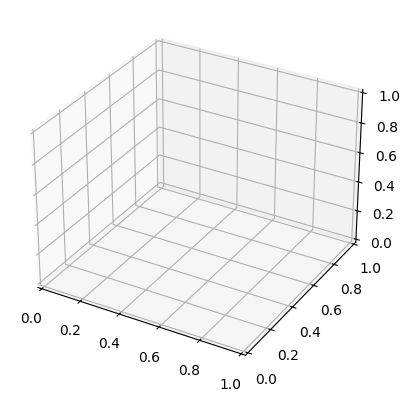

In [30]:
	from mpl_toolkits import mplot3d
	from ipywidgets import interact, fixed

	def plot_3D(elev=30, azim=30, X=X, y=y):
	    ax = plt.subplot(projection='3d')
	    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
	    ax.view_init(elev=elev, azim=azim)
	    ax.set_xlabel('x')
	    ax.set_ylabel('y')
	    ax.set_zlabel('r')

	interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
	         X=fixed(X), y=fixed(y))

In [31]:
	clf = SVC(kernel='rbf', C=1E6)
	clf.fit(X, y)

SVC(C=1000000.0)

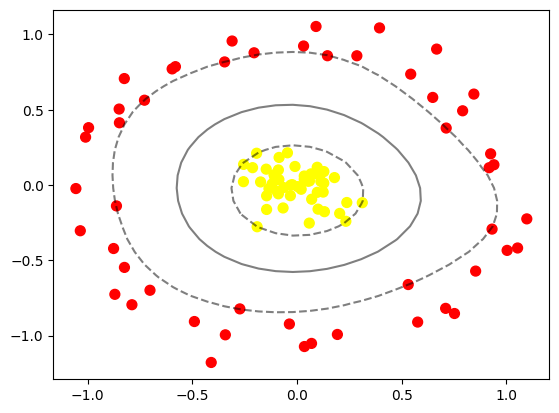

In [32]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf)
	plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
	            s=300, lw=1, facecolors='none')

Praktikum 3 - SVM Data Overlapping

In [33]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC
	from sklearn.datasets import make_blobs

In [34]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

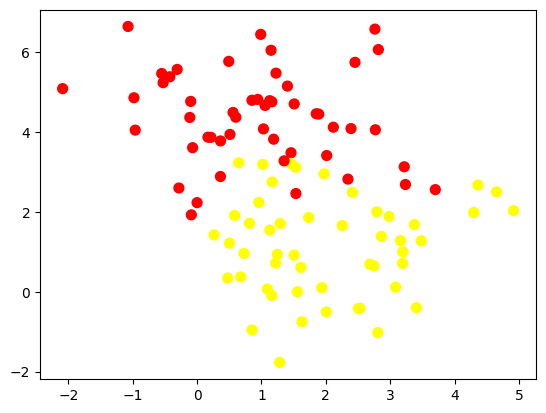

In [35]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=1.2)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

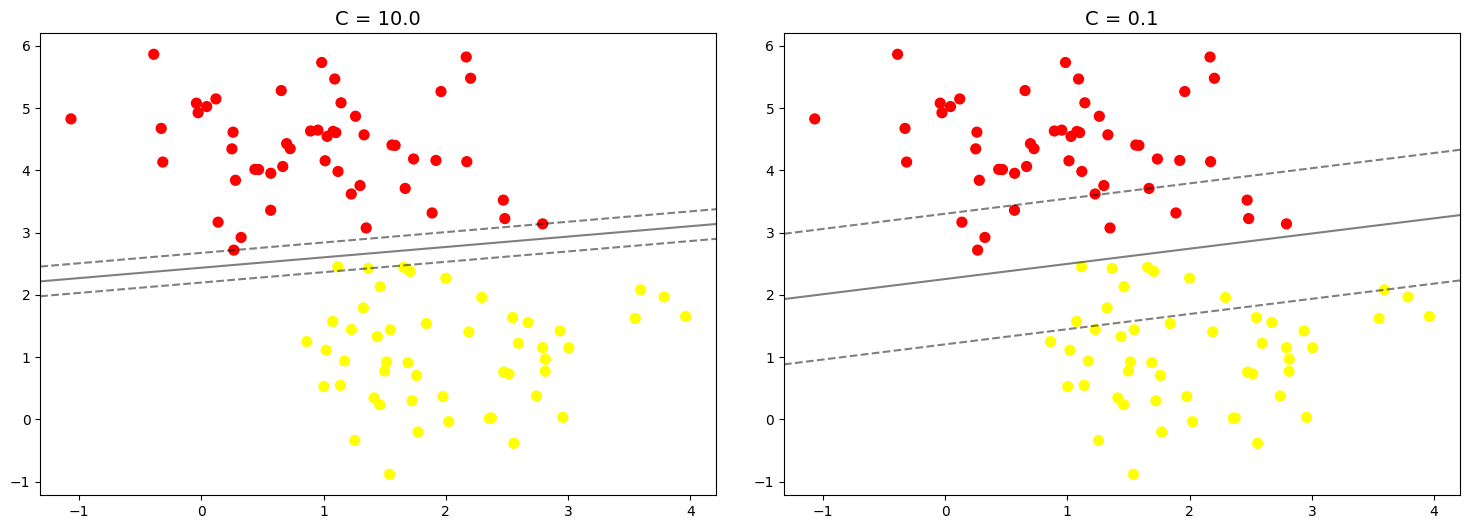

In [36]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=0.8)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

	for axi, C in zip(ax, [10.0, 0.1]):
	    model = SVC(kernel='linear', C=C).fit(X, y)
	    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    plot_svc_decision_function(model, axi)
	    axi.scatter(model.support_vectors_[:, 0],
	                model.support_vectors_[:, 1],
	                s=300, lw=1, facecolors='none');
	    axi.set_title('C = {0:.1f}'.format(C), size=14)